# Deep Learning Assignment 02 — CNN Architectures, Training & Ablations
**Framework:** TensorFlow/Keras | **Platform:** Colab T4 | **Seed:** 42


## Part I

### Q1. Shape / parameter trace (input 96x96x3)
Formulas: output size (SAME) = ceil(H/stride). Conv params = k*k*C_in*C_out + C_out. MACs (one conv) = H_out*W_out*C_out*(k*k*C_in). Dense params = in*out + out.

| Layer | Output shape | Trainable params |
|---|---|---|
| Input | 96x96x3 | 0 |
| Conv2D(32, 5, s2, same) | 48x48x32 | 5*5*3*32 + 32 = **2,432** |
| MaxPool2D(2, s2) | 24x24x32 | 0 |
| Conv2D(64, 3, s1, same) | 24x24x64 | 3*3*32*64 + 64 = **18,496** |
| GlobalAveragePooling2D | 64 | 0 |
| Dense(10) | 10 | 64*10 + 10 = **650** |
| **Total** | | **21,578** |

MACs of first conv = 48*48*32*(5*5*3) = 2304*32*75 = **5,529,600 MACs** (assumes bias adds are not counted as MACs; 1 MAC = 1 multiply + 1 add).

### Q2. Why VGG uses 3x3 layers (C = 64 in/out, no bias)
| Design | Receptive field | Weights |
|---|---|---|
| one 7x7 | 7x7 | 7*7*64*64 = **200,704** |
| three 3x3 | 1+2+2+2 = 7x7 | 3*(3*3*64*64) = **110,592** |

Same 7x7 receptive field with **45% fewer weights** (27C^2 vs 49C^2). The stack also has **three ReLUs instead of one**, so the function is more non-linear and more discriminative, and the deeper graph builds features hierarchically (edges -> textures -> parts). It costs more activation memory and layers, but fewer parameters/MACs.

### Q3. Inception arithmetic (input 28x28x192)
| Branch | Weights | Output |
|---|---|---|
| (i) 1x1->64 | 192*64 = 12,288 | 28x28x64 |
| (ii) 1x1->32, 3x3->128 | 192*32 + 3*3*32*128 = 6,144 + 36,864 = 43,008 | 28x28x128 |
| (iii) 1x1->16, 5x5->32 | 192*16 + 5*5*16*32 = 3,072 + 12,800 = 15,872 | 28x28x32 |
| (iv) maxpool3x3 -> 1x1->32 | 192*32 = 6,144 | 28x28x32 |

Concatenation: 64+128+32+32 = **28x28x256**. Total weights = **77,312**.
Without the reductions: (ii) 3*3*192*128 = 221,184; (iii) 5*5*192*32 = 153,600. Total = 12,288+221,184+153,600+6,144 = **393,216** (about **5.1x more**). The 1x1 bottlenecks shrink channels *before* the expensive big kernels.

### Q4. Residual + BN reasoning
x: 32x32x64, F(x): 16x16x128. Projection shortcut: **Conv2D(128, kernel 1x1, stride 2, no bias)** gives 16x16x128; weights = 1*1*64*128 = **8,192** (a BN on the shortcut would add 2*128 trainable params).
Output: y = F(x) + W_s x (then ReLU in ResNet-v1). For an identity shortcut y = F(x) + x, so dL/dx = dL/dy * (1 + dF/dx): the **"1" is the direct identity-gradient pathway** that lets gradients reach early layers without being multiplied through every weight layer. With a projection, that path goes through W_s instead of an exact identity (still short, but not exactly 1).
**BatchNorm (NHWC):** in training, for each channel c it computes mean and variance over the N, H, W axes of the current mini-batch, normalizes x_hat = (x-mu_B)/sqrt(var_B+eps), outputs gamma*x_hat+beta, and updates moving averages of mean/var. At inference it uses the stored moving mean/var (no dependence on the batch).

In [1]:
# Verify Part I numbers
ceil = lambda a: -(-a // 1)
c1 = 5*5*3*32+32; c2 = 3*3*32*64+64; d = 64*10+10
print("Q1 params:", c1, c2, d, "total", c1+c2+d, "| first conv MACs:", 48*48*32*(5*5*3))
print("Q2:", 7*7*64*64, 3*3*3*64*64, "saving %.1f%%" % (100*(1-3*9/49)))
b1=192*64; b2=192*32+9*32*128; b3=192*16+25*16*32; b4=192*32
print("Q3 branches:", b1,b2,b3,b4,"total",b1+b2+b3+b4, "concat channels", 64+128+32+32)
nr = b1 + 9*192*128 + 25*192*32 + b4
print("Q3 no reductions:", nr, "ratio %.2fx" % (nr/(b1+b2+b3+b4)))
print("Q4 projection weights:", 1*1*64*128)

Q1 params: 2432 18496 650 total 21578 | first conv MACs: 5529600
Q2: 200704 110592 saving 44.9%
Q3 branches: 12288 43008 15872 6144 total 77312 concat channels 256
Q3 no reductions: 393216 ratio 5.09x
Q4 projection weights: 8192


## Setup, data protocol and helpers
**What happens here and why**
- CIFAR-10 images are only 32x32; the historical networks expect much larger inputs. We upsample to 96x96 *inside the tf.data pipeline* (so we never store enlarged copies). Upsampling adds no new detail, it only gives the networks enough spatial size.
- A fixed **stratified 12,000-image train** subset and a **disjoint 3,000-image validation** subset come only from the original 50,000 training images. The 10,000 test images are untouched until the very end.
- `mixed_float16` speeds up the T4 and saves memory; the final Dense layer stays float32 so the logits/loss are numerically safe.

In [2]:
import os, sys, time, json, gc, random, platform, subprocess
import numpy as np, pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt

SEED = 42
BATCH = 32
ARCH_SIZE, ABL_SIZE = 96, 64
ARCH_EPOCHS = 5          # assignment maximum for the four scratch architectures
ABL_EPOCHS = 10          # A0-A3 ablation epochs
A4F_EPOCHS, A4T_EPOCHS = 5, 5
ABL_SEEDS = [42, 123]    # set to [42] if you run out of time/quota
RUN_LR_SANITY = True
OUT = "outputs"
os.makedirs(OUT + "/ckpt", exist_ok=True)

keras.utils.set_random_seed(SEED)
print("TF", tf.__version__, "| Keras", keras.__version__, "| Python", platform.python_version())
gpus = tf.config.list_physical_devices("GPU"); print("GPUs:", gpus)
try:
    smi = subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout
except Exception as e:
    smi = "nvidia-smi unavailable: %s" % e
print(smi); open(OUT + "/nvidia_smi.txt", "w").write(smi)
with open(OUT + "/environment.txt", "w") as f:
    f.write("tensorflow==%s\nkeras==%s\nnumpy==%s\npandas==%s\n" % (tf.__version__, keras.__version__, np.__version__, pd.__version__))
if gpus:
    keras.mixed_precision.set_global_policy("mixed_float16")   # final Dense uses dtype float32
print("Policy:", keras.mixed_precision.global_policy())

TF 2.21.0 | Keras 3.13.2 | Python 3.13.16
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Fri Nov 20 18:00:09 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   55C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                        

In [3]:
(x_all, y_all), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_all, y_test = y_all.ravel(), y_test.ravel()
idx = np.arange(len(x_all))
idx_tr, idx_rest = train_test_split(idx, train_size=12000, stratify=y_all, random_state=SEED)
idx_val, _ = train_test_split(idx_rest, train_size=3000, stratify=y_all[idx_rest], random_state=SEED)
assert len(set(idx_tr) & set(idx_val)) == 0
x_tr, y_tr, x_val, y_val = x_all[idx_tr], y_all[idx_tr], x_all[idx_val], y_all[idx_val]
json.dump({"train_idx": idx_tr.tolist(), "val_idx": idx_val.tolist(), "seed": SEED}, open(OUT + "/data_indices.json", "w"))
print(x_tr.shape, x_val.shape, "test (held out):", x_test.shape)
print("train class counts:", np.bincount(y_tr), "val:", np.bincount(y_val))
CLASSES = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]

def make_ds(x, y, size, train, mode="scratch", batch=BATCH, seed=SEED):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if train:
        ds = ds.shuffle(len(x), seed=seed, reshuffle_each_iteration=True)
    def prep(img, lab):
        img = tf.image.resize(tf.cast(img, tf.float32), (size, size), method="bilinear")  # resize on demand
        if mode == "scratch":
            img = img / 255.0
        else:  # transfer learning: ResNet50 preprocessing expects original 0-255 pixels
            img = keras.applications.resnet50.preprocess_input(img)
        return img, lab
    return ds.map(prep, num_parallel_calls=tf.data.AUTOTUNE).batch(batch).prefetch(tf.data.AUTOTUNE)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1223s 7us/step
(12000, 32, 32, 3) (3000, 32, 32, 3) test (held out): (10000, 32, 32, 3)
train class counts: [1200 1200 1200 1200 1200 1200 1200 1200 1200 1200] val: [300 300 300 300 300 300 300 300 300 300]


## Part II — Four architectures
- **AlexNet (2012):** first deep CNN to win ImageNet; ReLU, dropout, GPU training, big 11x11 first filter.
- **VGG16 (2014):** show that depth with tiny 3x3 kernels is enough; very regular design (2,2,3,3,3 conv layers). Huge FC layers hold most parameters.
- **GoogLeNet / Inception-v1 (2014):** parallel multi-scale branches with 1x1 bottlenecks give high accuracy with far fewer parameters; global average pooling replaces big FC layers.
- **ResNet-18 (2015):** identity shortcuts (y = F(x)+x) fix the degradation problem, so deeper nets become trainable.

### Deviation table
| Model | Original | What we did | Why |
|---|---|---|---|
| AlexNet | 224x224 input, LRN, 2-GPU grouped convs, 1000 classes | 96x96 input; conv1 uses SAME padding (96->24) so spatial size survives; **LRN omitted**; **grouped convs omitted** (single full-connection stack); 10-way logits head; dropout 0.5 | LRN is obsolete (replaced by BN) and adds little; grouping was only a 2-GPU memory workaround; small input needs padding |
| VGG16 | 224x224, 1000 classes | 96x96 -> final feature map 3x3x512 = 4608 inputs to FC4096; 10 classes | Smaller image/class count |
| GoogLeNet | 224x224, LRN, 2 auxiliary classifiers | 96x96; **LRN omitted; auxiliary classifiers described, not trained**; 10-way head; SAME padding | Short training budget; aux heads were for gradient help in a 22-layer no-BN net |
| ResNet-18 | 224x224, 1000 classes | 96x96, standard 7x7/2 stem + maxpool; BN after each conv; 1x1 projection when shape changes | Smaller image/class count |

All four share: Adam 3e-4, sparse CE from_logits=True, seed 42, 5 epochs, checkpoint = best val accuracy.

In [4]:
HE = "he_normal"

def build_alexnet(size=96):
    i = keras.Input((size, size, 3))
    x = layers.Conv2D(96, 11, strides=4, padding="same", activation="relu", kernel_initializer=HE, name="conv1")(i)  # 24x24
    x = layers.MaxPool2D(3, strides=2, name="pool1")(x)                                                              # 11x11
    x = layers.Conv2D(256, 5, padding="same", activation="relu", kernel_initializer=HE, name="conv2")(x)
    x = layers.MaxPool2D(3, strides=2, name="pool2")(x)                                                              # 5x5
    x = layers.Conv2D(384, 3, padding="same", activation="relu", kernel_initializer=HE, name="conv3")(x)
    x = layers.Conv2D(384, 3, padding="same", activation="relu", kernel_initializer=HE, name="conv4")(x)
    x = layers.Conv2D(256, 3, padding="same", activation="relu", kernel_initializer=HE, name="conv5")(x)
    x = layers.MaxPool2D(3, strides=2, name="pool5")(x)                                                              # 2x2
    x = layers.Flatten()(x)
    x = layers.Dense(4096, activation="relu", kernel_initializer=HE, name="fc6")(x); x = layers.Dropout(0.5)(x)
    x = layers.Dense(4096, activation="relu", kernel_initializer=HE, name="fc7")(x); x = layers.Dropout(0.5)(x)
    o = layers.Dense(10, dtype="float32", name="logits")(x)
    return keras.Model(i, o, name="AlexNet")

def build_vgg16(size=96):
    i = keras.Input((size, size, 3)); x = i
    for b, (n, f) in enumerate(zip([2, 2, 3, 3, 3], [64, 128, 256, 512, 512]), start=1):
        for k in range(1, n + 1):
            x = layers.Conv2D(f, 3, padding="same", activation="relu", kernel_initializer=HE, name="block%d_conv%d" % (b, k))(x)
        x = layers.MaxPool2D(2, strides=2, name="block%d_pool" % b)(x)
    x = layers.Flatten()(x)                                                       # 3*3*512 = 4608
    x = layers.Dense(4096, activation="relu", kernel_initializer=HE, name="fc1")(x); x = layers.Dropout(0.5)(x)
    x = layers.Dense(4096, activation="relu", kernel_initializer=HE, name="fc2")(x); x = layers.Dropout(0.5)(x)
    o = layers.Dense(10, dtype="float32", name="logits")(x)
    return keras.Model(i, o, name="VGG16")

def conv_relu(x, f, k, s=1, name=None):
    return layers.Conv2D(f, k, strides=s, padding="same", activation="relu", kernel_initializer=HE, name=name)(x)

def inception(x, f1, f3r, f3, f5r, f5, fp, name):
    b1 = conv_relu(x, f1, 1, name=name + "_1x1")
    b2 = conv_relu(conv_relu(x, f3r, 1, name=name + "_3x3red"), f3, 3, name=name + "_3x3")
    b3 = conv_relu(conv_relu(x, f5r, 1, name=name + "_5x5red"), f5, 5, name=name + "_5x5")
    b4 = layers.MaxPool2D(3, strides=1, padding="same", name=name + "_pool")(x)
    b4 = conv_relu(b4, fp, 1, name=name + "_poolproj")
    assert b1.shape[1:3] == b2.shape[1:3] == b3.shape[1:3] == b4.shape[1:3]
    return layers.Concatenate(name=name + "_concat")([b1, b2, b3, b4])

def build_googlenet(size=96):
    i = keras.Input((size, size, 3))
    x = conv_relu(i, 64, 7, 2, "stem_conv7")                               # 48
    x = layers.MaxPool2D(3, strides=2, padding="same")(x)                  # 24
    x = conv_relu(x, 64, 1, name="stem_conv1")
    x = conv_relu(x, 192, 3, name="stem_conv3")
    x = layers.MaxPool2D(3, strides=2, padding="same")(x)                  # 12
    x = inception(x, 64, 96, 128, 16, 32, 32, "3a")
    x = inception(x, 128, 128, 192, 32, 96, 64, "3b")
    x = layers.MaxPool2D(3, strides=2, padding="same")(x)                  # 6
    x = inception(x, 192, 96, 208, 16, 48, 64, "4a")
    x = inception(x, 160, 112, 224, 24, 64, 64, "4b")
    x = inception(x, 128, 128, 256, 24, 64, 64, "4c")
    x = inception(x, 112, 144, 288, 32, 64, 64, "4d")
    x = inception(x, 256, 160, 320, 32, 128, 128, "4e")
    x = layers.MaxPool2D(3, strides=2, padding="same")(x)                  # 3
    x = inception(x, 256, 160, 320, 32, 128, 128, "5a")
    x = inception(x, 384, 192, 384, 48, 128, 128, "5b")
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    o = layers.Dense(10, dtype="float32", name="logits")(x)
    return keras.Model(i, o, name="GoogLeNet")

def basic_block(x, f, stride, name):
    y = layers.Conv2D(f, 3, strides=stride, padding="same", use_bias=False, kernel_initializer=HE, name=name + "_c1")(x)
    y = layers.ReLU()(layers.BatchNormalization(name=name + "_bn1")(y))
    y = layers.Conv2D(f, 3, padding="same", use_bias=False, kernel_initializer=HE, name=name + "_c2")(y)
    y = layers.BatchNormalization(name=name + "_bn2")(y)
    s = x
    if stride != 1 or x.shape[-1] != f:                                    # 1x1 projection shortcut
        s = layers.Conv2D(f, 1, strides=stride, padding="same", use_bias=False, kernel_initializer=HE, name=name + "_proj")(x)
        s = layers.BatchNormalization(name=name + "_projbn")(s)
    assert tuple(y.shape[1:]) == tuple(s.shape[1:]), "Add shape mismatch in %s: %s vs %s" % (name, y.shape, s.shape)
    return layers.ReLU(name=name + "_out")(layers.Add(name=name + "_add")([y, s]))

def build_resnet18(size=96):
    i = keras.Input((size, size, 3))
    x = layers.Conv2D(64, 7, strides=2, padding="same", use_bias=False, kernel_initializer=HE, name="stem_conv")(i)
    x = layers.ReLU()(layers.BatchNormalization(name="stem_bn")(x))
    x = layers.MaxPool2D(3, strides=2, padding="same")(x)
    for si, f in enumerate([64, 128, 256, 512], start=1):
        for bi in range(2):
            x = basic_block(x, f, 2 if (bi == 0 and si > 1) else 1, "s%db%d" % (si, bi + 1))
    x = layers.GlobalAveragePooling2D()(x)
    o = layers.Dense(10, dtype="float32", name="logits")(x)
    return keras.Model(i, o, name="ResNet18")

ARCHS = {"AlexNet": build_alexnet, "VGG16": build_vgg16, "InceptionV1": build_googlenet, "ResNet18": build_resnet18}

### Evidence: forward pass, summaries, diagrams, manual parameter check
For each model we (a) push a 2x96x96x3 batch and require 2x10 logits, (b) save `model.summary()` and a diagram, and (c) check one layer's parameter count by hand against Keras.

In [5]:
def forward_check(m, size=96):
    out = m(np.random.rand(2, size, size, 3).astype("float32"))
    assert tuple(out.shape) == (2, 10), out.shape
    return tuple(out.shape)

manual = {  # (model, layer, hand-computed params)
    "AlexNet": ("conv1", 11*11*3*96 + 96),                  # 34,944
    "VGG16": ("block1_conv1", 3*3*3*64 + 64),               # 1,792
    "InceptionV1": ("stem_conv7", 7*7*3*64 + 64),           # 9,472
    "ResNet18": ("stem_conv", 7*7*3*64),                    # 9,408 (no bias)
}
for name, fn in ARCHS.items():
    keras.backend.clear_session(); gc.collect()
    m = fn(ARCH_SIZE)
    print(name, "forward logits shape:", forward_check(m), "| total params: {:,}".format(m.count_params()))
    lname, hand = manual[name]
    assert m.get_layer(lname).count_params() == hand
    print("   manual check %s: hand=%d keras=%d OK" % (lname, hand, m.get_layer(lname).count_params()))
    with open("%s/%s_summary.txt" % (OUT, name), "w") as f:
        m.summary(print_fn=lambda s, **k: f.write(s + "\n"))
    try:
        keras.utils.plot_model(m, to_file="%s/%s_diagram.png" % (OUT, name), show_shapes=True, dpi=60)
    except Exception as e:
        print("   (diagram skipped: %s)" % e)
vgg = build_vgg16(); print("VGG16 conv layers:", sum(isinstance(l, layers.Conv2D) for l in vgg.layers), "dense layers:", sum(isinstance(l, layers.Dense) for l in vgg.layers))
# Analytical VGG head comparison (no extra run): FC-head vs GAP-head
fc_head = 4608*4096+4096 + 4096*4096+4096 + 4096*10+10
gap_head = 512*10+10
print("VGG16 FC head params (96x96): {:,} | GAP head: {:,} | canonical 224x224 first FC alone: {:,}".format(fc_head, gap_head, 7*7*512*4096+4096))
print("Total VGG16 now: {:,}; with GAP head it would be about {:,}".format(vgg.count_params(), vgg.count_params()-fc_head+gap_head))
# ResNet-18 Add-shape assertions are executed inside basic_block() while building the model (passed above).

AlexNet forward logits shape: (2, 10) | total params: 24,767,882
   manual check conv1: hand=34944 keras=34944 OK


VGG16 forward logits shape: (2, 10) | total params: 50,415,434
   manual check block1_conv1: hand=1792 keras=1792 OK


InceptionV1 forward logits shape: (2, 10) | total params: 5,983,802
   manual check stem_conv7: hand=9472 keras=9472 OK


ResNet18 forward logits shape: (2, 10) | total params: 11,191,242
   manual check stem_conv: hand=9408 keras=9408 OK


VGG16 conv layers: 13 dense layers: 3
VGG16 FC head params (96x96): 35,700,746 | GAP head: 5,130 | canonical 224x224 first FC alone: 102,764,544
Total VGG16 now: 50,415,434; with GAP head it would be about 14,719,818


## Training/evaluation engine (shared by every run)
Same rules for all runs: Adam, sparse CE with `from_logits=True`, checkpoint on best **validation accuracy**, then reload the best weights and compute macro-F1 on the validation set.
Generalization gap = final-epoch train accuracy minus final-epoch validation accuracy (train accuracy is measured with dropout/augmentation active, so it is a rough indicator).
If a run hits GPU OOM it is retried with batch 16 and the failure is logged (never hidden).

In [6]:
RESULTS, HIST, FAILED, REG = [], {}, [], {}
TRAIN_CACHE = {}

def clear():
    keras.backend.clear_session(); gc.collect()

def trainable_total(m):
    return int(sum(np.prod(w.shape) for w in m.trainable_weights)), int(m.count_params())

def fit_eval(run_id, arch, model, size, epochs, seed, lr, mode="scratch", batch=BATCH, caveat="", compile_model=True):
    ds_tr = make_ds(x_tr, y_tr, size, True, mode, batch, seed)
    ds_va = make_ds(x_val, y_val, size, False, mode, batch, seed)
    if compile_model:
        model.compile(optimizer=keras.optimizers.Adam(lr),
                      loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
    ckpt = "%s/ckpt/%s.weights.h5" % (OUT, run_id)
    cb = [keras.callbacks.ModelCheckpoint(ckpt, monitor="val_accuracy", mode="max", save_best_only=True, save_weights_only=True)]
    try: tf.config.experimental.reset_memory_stats("GPU:0")
    except Exception: pass
    t0 = time.time()
    h = model.fit(ds_tr, validation_data=ds_va, epochs=epochs, callbacks=cb, verbose=2)
    mins = (time.time() - t0) / 60
    model.load_weights(ckpt)
    pred = model.predict(ds_va, verbose=0).argmax(1)
    f1 = f1_score(y_val, pred, average="macro")
    try: peak = tf.config.experimental.get_memory_info("GPU:0")["peak"] / 1e6
    except Exception: peak = np.nan
    tr, tot = trainable_total(model)
    H = {k: [float(v) for v in vs] for k, vs in h.history.items()}
    HIST[run_id] = H
    row = {"run_id": run_id, "architecture": arch, "input_size": size, "seed": seed,
           "trainable_params": tr, "total_params": tot, "epochs": epochs, "batch": batch, "lr": lr,
           "best_val_acc": max(H["val_accuracy"]), "macro_f1": f1, "final_train_acc": H["accuracy"][-1],
           "gen_gap": H["accuracy"][-1] - H["val_accuracy"][-1], "train_minutes": mins, "peak_gpu_mb": peak, "caveat": caveat}
    RESULTS.append(row)
    pd.DataFrame(RESULTS).to_csv(OUT + "/results.csv", index=False)
    json.dump(HIST, open(OUT + "/histories.json", "w"))
    print(">>> %s | best val acc %.4f | macro-F1 %.4f | %.1f min" % (run_id, row["best_val_acc"], f1, mins))
    return row

def run_safe(run_id, arch, build, size, epochs, seed, lr, mode="scratch", caveat=""):
    REG[run_id] = {"build": build, "size": size, "mode": mode}
    for b in [BATCH, 16]:
        try:
            clear(); keras.utils.set_random_seed(seed)
            m = build()
            return fit_eval(run_id, arch, m, size, epochs, seed, lr, mode, b, caveat + ("" if b == BATCH else " [OOM at batch %d -> retried with %d]" % (BATCH, b)))
        except tf.errors.ResourceExhaustedError as e:
            FAILED.append({"run_id": run_id, "batch": b, "error": "OOM"}); json.dump(FAILED, open(OUT + "/failed_runs.json", "w"))
            print("!!! OOM for %s at batch %d" % (run_id, b))
    return None

Adam 3e-4 is the *common* benchmark, but a very deep plain network (VGG16 without BatchNorm) can sit at 10% accuracy if the LR is wrong. We train each model for 2 short epochs on 3,000 images at 3 learning rates and just look at the numbers.

In [7]:
if RUN_LR_SANITY:
    sub = np.random.RandomState(SEED).choice(len(x_tr), 3000, replace=False)
    sanity = []
    for name, fn in ARCHS.items():
        for lr in [1e-3, 3e-4, 1e-4]:
            clear(); keras.utils.set_random_seed(SEED)
            m = fn(ARCH_SIZE)
            m.compile(optimizer=keras.optimizers.Adam(lr), loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
            h = m.fit(make_ds(x_tr[sub], y_tr[sub], ARCH_SIZE, True), validation_data=make_ds(x_val[:1000], y_val[:1000], ARCH_SIZE, False), epochs=2, verbose=0)
            sanity.append({"model": name, "lr": lr, "val_acc_after_2_epochs": h.history["val_accuracy"][-1]})
            print(sanity[-1])
    pd.DataFrame(sanity).pivot(index="model", columns="lr", values="val_acc_after_2_epochs").to_csv(OUT + "/lr_sanity.csv")
    display(pd.DataFrame(sanity).pivot(index="model", columns="lr", values="val_acc_after_2_epochs"))

{'model': 'AlexNet', 'lr': 0.001, 'val_acc_after_2_epochs': 0.2619999945163727}
{'model': 'AlexNet', 'lr': 0.0003, 'val_acc_after_2_epochs': 0.32100000977516174}
{'model': 'AlexNet', 'lr': 0.0001, 'val_acc_after_2_epochs': 0.3400000035762787}
{'model': 'VGG16', 'lr': 0.001, 'val_acc_after_2_epochs': 0.10599999874830246}
{'model': 'VGG16', 'lr': 0.0003, 'val_acc_after_2_epochs': 0.12999999523162842}
{'model': 'VGG16', 'lr': 0.0001, 'val_acc_after_2_epochs': 0.2750000059604645}
{'model': 'InceptionV1', 'lr': 0.001, 'val_acc_after_2_epochs': 0.13099999725818634}
{'model': 'InceptionV1', 'lr': 0.0003, 'val_acc_after_2_epochs': 0.2290000021457672}
{'model': 'InceptionV1', 'lr': 0.0001, 'val_acc_after_2_epochs': 0.29499998688697815}
{'model': 'ResNet18', 'lr': 0.001, 'val_acc_after_2_epochs': 0.3070000112056732}
{'model': 'ResNet18', 'lr': 0.0003, 'val_acc_after_2_epochs': 0.16200000047683716}
{'model': 'ResNet18', 'lr': 0.0001, 'val_acc_after_2_epochs': 0.2199999988079071}


lr,0.0001,0.0003,0.0010
model,,,
AlexNet,0.340,0.321,0.262
InceptionV1,0.295,0.229,0.131
ResNet18,0.220,0.162,0.307
VGG16,0.275,0.130,0.106


## Four architecture benchmarks (one documented seed each, 96x96, 5 epochs)

In [8]:
ARCH_LR = 3e-4
for name, fn in ARCHS.items():
    run_safe("ARCH_" + name, name, lambda fn=fn: fn(ARCH_SIZE), ARCH_SIZE, ARCH_EPOCHS, SEED, ARCH_LR,
             caveat="historical arch, different params/FLOPs; single seed (provisional)")
display(pd.DataFrame(RESULTS))

Epoch 1/5
375/375 - 20s - 53ms/step - accuracy: 0.3104 - loss: 1.8624 - val_accuracy: 0.4397 - val_loss: 1.5450
Epoch 2/5
375/375 - 13s - 34ms/step - accuracy: 0.4627 - loss: 1.4563 - val_accuracy: 0.4463 - val_loss: 1.4937
Epoch 3/5
375/375 - 14s - 37ms/step - accuracy: 0.5537 - loss: 1.2385 - val_accuracy: 0.5380 - val_loss: 1.3195
Epoch 4/5
375/375 - 11s - 29ms/step - accuracy: 0.6190 - loss: 1.0790 - val_accuracy: 0.5757 - val_loss: 1.2031
Epoch 5/5
375/375 - 8s - 21ms/step - accuracy: 0.6757 - loss: 0.9176 - val_accuracy: 0.5677 - val_loss: 1.2464
>>> ARCH_AlexNet | best val acc 0.5757 | macro-F1 0.5607 | 1.1 min
Epoch 1/5
375/375 - 82s - 218ms/step - accuracy: 0.1694 - loss: 2.2127 - val_accuracy: 0.2817 - val_loss: 1.9036
Epoch 2/5
375/375 - 58s - 155ms/step - accuracy: 0.3236 - loss: 1.7830 - val_accuracy: 0.3823 - val_loss: 1.7271
Epoch 3/5
375/375 - 64s - 171ms/step - accuracy: 0.4130 - loss: 1.5669 - val_accuracy: 0.4593 - val_loss: 1.4928
Epoch 4/5
375/375 - 66s - 176ms/ste

,run_id,architecture,input_size,seed,trainable_params,total_params,epochs,batch,lr,best_val_acc,macro_f1,final_train_acc,gen_gap,train_minutes,peak_gpu_mb,caveat
0,ARCH_AlexNet,AlexNet,96,42,24767882,24767882,5,32,0.0003,0.575667,0.560679,0.675667,0.108000,1.097668,4288.889856,"historical arch, different params/FLOPs; singl..."
1,ARCH_VGG16,VGG16,96,42,50415434,50415434,5,32,0.0003,0.539333,0.533266,0.548667,0.009333,5.589262,5811.646720,"historical arch, different params/FLOPs; singl..."
2,ARCH_InceptionV1,InceptionV1,96,42,5983802,5983802,5,32,0.0003,0.534000,0.529751,0.557083,0.023083,2.577813,5159.622656,"historical arch, different params/FLOPs; singl..."
3,ARCH_ResNet18,ResNet18,96,42,11181642,11191242,5,32,0.0003,0.558667,0.554655,0.857583,0.298917,1.865652,5183.187712,"historical arch, different params/FLOPs; singl..."


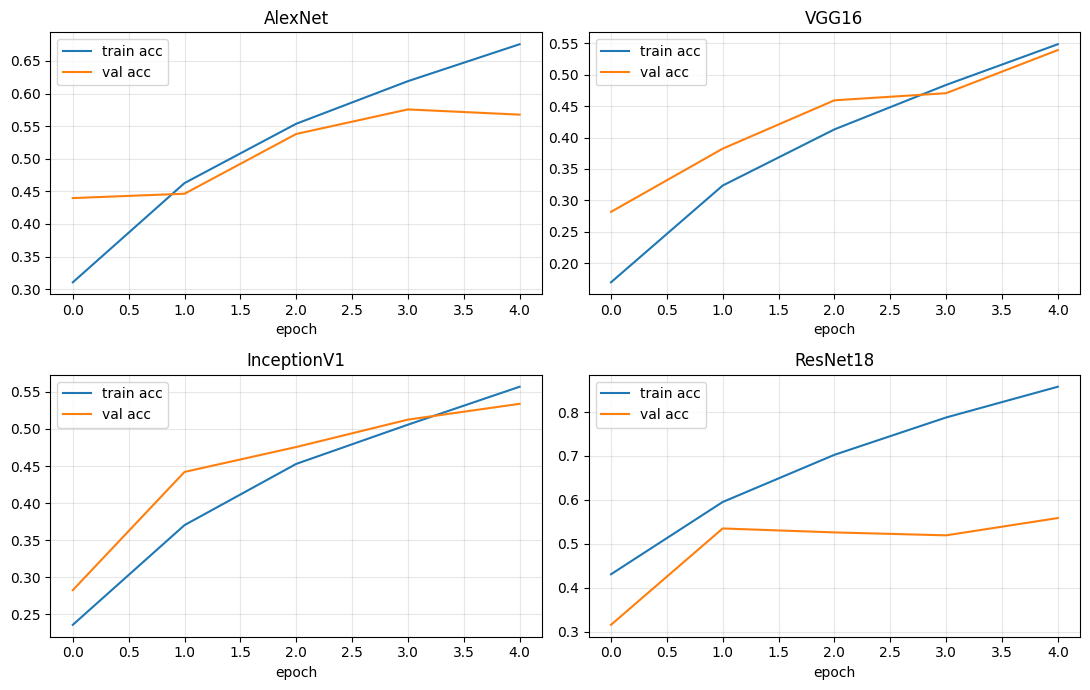

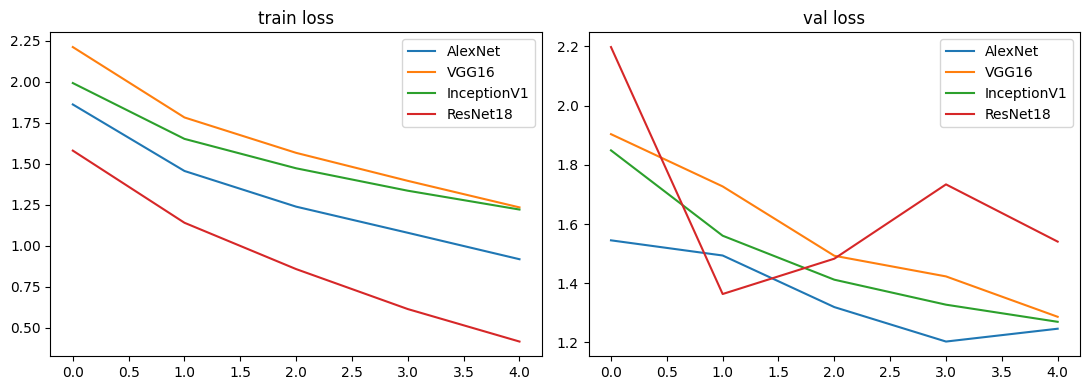

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, name in zip(axes.ravel(), ARCHS):
    H = HIST.get("ARCH_" + name)
    if H:
        ax.plot(H["accuracy"], label="train acc"); ax.plot(H["val_accuracy"], label="val acc")
        ax.set_title(name); ax.set_xlabel("epoch"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT + "/arch_curves.png", dpi=130); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in ARCHS:
    H = HIST.get("ARCH_" + name)
    if H: axes[0].plot(H["loss"], label=name); axes[1].plot(H["val_loss"], label=name)
axes[0].set_title("train loss"); axes[1].set_title("val loss"); [a.legend() or a.grid(alpha=.3) for a in axes]
plt.tight_layout(); plt.savefig(OUT + "/arch_loss_curves.png", dpi=130); plt.show()

- **AlexNet:** Won ImageNet 2012 by a large margin and showed that deep CNNs trained on GPUs with ReLU and dropout beat hand-crafted features. It restarted the deep-learning era in vision.
- **VGG16:** Showed that depth matters and that stacks of 3x3 convolutions replace larger kernels with fewer weights and more non-linearity. Its simple, uniform design became a standard backbone, though its huge FC layers are expensive.
- **GoogLeNet:** Introduced the Inception module, multi-scale parallel branches with 1x1 bottlenecks, reaching high accuracy with about 12x fewer parameters than AlexNet. Global average pooling removed most FC parameters.
- **ResNet-18:** Residual shortcuts (y = F(x)+x) solved the degradation problem where deeper plain nets train worse, making 50-1000-layer networks trainable. It is the basis of most modern vision backbones.

## Part III — Controlled ablation A0-A4 (25 marks), 64x64

In [10]:
def cbr(x, f):
    x = layers.Conv2D(f, 3, padding="same", use_bias=False, kernel_initializer=HE)(x)
    return layers.ReLU()(layers.BatchNormalization()(x))

def build_abl(variant, seed, size=ABL_SIZE):
    i = keras.Input((size, size, 3)); x = i
    if variant in ("A2", "A3-P", "A3-R"):
        x = keras.Sequential([layers.RandomFlip("horizontal", seed=seed),
                              layers.RandomTranslation(0.1, 0.1, seed=seed),
                              layers.RandomContrast(0.1, seed=seed)], name="augment")(x)   # active only in training
    if variant in ("A0", "A1", "A2"):
        for f in (32, 64):
            x = layers.Conv2D(f, 3, padding="same", use_bias=(variant == "A0"), kernel_initializer=HE)(x)
            if variant != "A0": x = layers.BatchNormalization()(x)
            x = layers.MaxPool2D(2)(layers.ReLU()(x))
    else:
        for f in (32, 64, 128):
            x = cbr(x, f)                                   # transition conv (channel change)
            t = cbr(x, f)                                   # two-conv block: conv-BN-ReLU ...
            if variant == "A3-P":
                t = cbr(t, f); x = t                        # ... conv-BN-ReLU (plain)
            else:
                t = layers.Conv2D(f, 3, padding="same", use_bias=False, kernel_initializer=HE)(t)
                t = layers.BatchNormalization()(t)          # ... conv-BN, then identity shortcut
                assert tuple(t.shape[1:]) == tuple(x.shape[1:])
                x = layers.ReLU()(layers.Add()([x, t]))
            x = layers.MaxPool2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    o = layers.Dense(10, dtype="float32")(x)
    return keras.Model(i, o, name=variant)

for v in ["A0", "A1", "A2", "A3-P", "A3-R"]:
    clear(); m = build_abl(v, SEED); forward_check(m, ABL_SIZE)
    print(v, "params:", trainable_total(m))

A0 params: (20042, 20042)
A1 params: (20138, 20330)
A2 params: (20138, 20330)
A3-P params: (482730, 484074)
A3-R params: (482730, 484074)


In [11]:
ABL_CAVEAT = {"A0": "reference", "A1": "A0 + BatchNorm", "A2": "A1 + augmentation",
              "A3-P": "deeper plain; capacity changed vs A2", "A3-R": "A3-P + identity shortcuts (same params)"}
for seed in ABL_SEEDS:
    for v in ["A0", "A1", "A2", "A3-P", "A3-R"]:
        run_safe("%s_s%d" % (v, seed), v, lambda v=v, seed=seed: build_abl(v, seed), ABL_SIZE, ABL_EPOCHS, seed, 3e-4, caveat=ABL_CAVEAT[v])
abl = pd.DataFrame(RESULTS); abl = abl[abl.run_id.str.match(r"^A[0-3]")]
display(abl[["run_id", "trainable_params", "best_val_acc", "macro_f1", "final_train_acc", "gen_gap", "train_minutes"]])
display(abl.groupby("architecture")[["best_val_acc", "macro_f1"]].agg(["mean", "std"]))

Epoch 1/10
375/375 - 14s - 37ms/step - accuracy: 0.1785 - loss: 2.1855 - val_accuracy: 0.2163 - val_loss: 2.0833
Epoch 2/10
375/375 - 3s - 9ms/step - accuracy: 0.2465 - loss: 2.0408 - val_accuracy: 0.2530 - val_loss: 2.0193
Epoch 3/10
375/375 - 3s - 7ms/step - accuracy: 0.2649 - loss: 1.9962 - val_accuracy: 0.2623 - val_loss: 1.9821
Epoch 4/10
375/375 - 3s - 7ms/step - accuracy: 0.2746 - loss: 1.9679 - val_accuracy: 0.2967 - val_loss: 1.9604
Epoch 5/10
375/375 - 2s - 7ms/step - accuracy: 0.2931 - loss: 1.9453 - val_accuracy: 0.3087 - val_loss: 1.9269
Epoch 6/10
375/375 - 3s - 7ms/step - accuracy: 0.3051 - loss: 1.9197 - val_accuracy: 0.2940 - val_loss: 1.9229
Epoch 7/10
375/375 - 3s - 8ms/step - accuracy: 0.3103 - loss: 1.8978 - val_accuracy: 0.3060 - val_loss: 1.8819
Epoch 8/10
375/375 - 3s - 7ms/step - accuracy: 0.3226 - loss: 1.8757 - val_accuracy: 0.3383 - val_loss: 1.8661
Epoch 9/10
375/375 - 3s - 7ms/step - accuracy: 0.3339 - loss: 1.8542 - val_accuracy: 0.3460 - val_loss: 1.8473

,run_id,trainable_params,best_val_acc,macro_f1,final_train_acc,gen_gap,train_minutes
4,A0_s42,20042,0.348333,0.329875,0.340417,-0.007917,0.638571
5,A1_s42,20138,0.446333,0.447431,0.437583,-0.008750,0.619592
6,A2_s42,20138,0.451000,0.448257,0.429333,-0.021667,1.132672
7,A3-P_s42,482730,0.644000,0.635081,0.708250,0.064250,2.866486
8,A3-R_s42,482730,0.602667,0.600373,0.704167,0.101500,2.848920
9,A0_s123,20042,0.367333,0.351553,0.358667,-0.006333,0.527582
10,A1_s123,20138,0.418000,0.397095,0.435000,0.017000,0.608629
11,A2_s123,20138,0.424333,0.403119,0.424083,-0.000250,1.209374
12,A3-P_s123,482730,0.643667,0.629796,0.724417,0.080750,2.883426
13,A3-R_s123,482730,0.619000,0.617412,0.719500,0.113167,3.001166


best_val_acc            macro_f1          
                     mean       std      mean       std
architecture                                           
A0               0.357833  0.013435  0.340714  0.015329
A1               0.432167  0.020035  0.422263  0.035593
A2               0.437667  0.018856  0.425688  0.031917
A3-P             0.643833  0.000236  0.632438  0.003737
A3-R             0.610833  0.011549  0.608892  0.012049

### A4: transfer learning (separate branch, 96x96)
- **A4-F (feature extraction):** ResNet50 pretrained on ImageNet, whole backbone frozen, called with `training=False` so BN keeps its inference statistics. Only the GAP + Dense head trains. Inputs use `resnet50.preprocess_input` on original 0-255 pixels.
- **A4-T (fine-tuning):** start from the best A4-F checkpoint, unfreeze the last stage (`conv5_block*`, BatchNorm layers kept frozen), **recompile**, and train at a low learning rate (1e-5) so we do not destroy pretrained features.

In [12]:
A4_SIZE = 96
def build_a4(size=A4_SIZE):
    base = keras.applications.ResNet50(include_top=False, weights="imagenet", input_shape=(size, size, 3))
    base.trainable = False
    i = keras.Input((size, size, 3))
    x = base(i, training=False)
    x = layers.GlobalAveragePooling2D()(x); x = layers.Dropout(0.2)(x)
    o = layers.Dense(10, dtype="float32")(x)
    return keras.Model(i, o, name="A4_ResNet50"), base

clear(); keras.utils.set_random_seed(SEED)
a4, base = build_a4()
REG["A4-F_s42"] = {"build": lambda: build_a4()[0], "size": A4_SIZE, "mode": "resnet"}
fit_eval("A4-F_s42", "A4-F", a4, A4_SIZE, A4F_EPOCHS, SEED, 1e-3, mode="resnet",
         caveat="frozen ImageNet ResNet50 + head; NOT a one-factor step from A3 (init + external data)")

# A4-T: continue from best A4-F, unfreeze conv5 block (BN stays frozen), recompile at low LR
a4.load_weights("%s/ckpt/A4-F_s42.weights.h5" % OUT)
base.trainable = True
for l in base.layers:
    l.trainable = l.name.startswith("conv5_block") and not isinstance(l, layers.BatchNormalization)
a4.compile(optimizer=keras.optimizers.Adam(1e-5), loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
REG["A4-T_s42"] = {"build": lambda: build_a4()[0], "size": A4_SIZE, "mode": "resnet"}
fit_eval("A4-T_s42", "A4-T", a4, A4_SIZE, A4T_EPOCHS, SEED, 1e-5, mode="resnet", compile_model=False,
         caveat="fine-tune conv5 block from A4-F checkpoint; minutes = fine-tuning only")
display(pd.DataFrame(RESULTS)[["run_id", "trainable_params", "total_params", "best_val_acc", "macro_f1", "train_minutes"]].tail(2))

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/5
375/375 - 51s - 136ms/step - accuracy: 0.7361 - loss: 0.9335 - val_accuracy: 0.8353 - val_loss: 0.5593
Epoch 2/5
375/375 - 50s - 134ms/step - accuracy: 0.8276 - loss: 0.5689 - val_accuracy: 0.8367 - val_loss: 0.5755
Epoch 3/5
375/375 - 12s - 32ms/step - accuracy: 0.8522 - loss: 0.4710 - val_accuracy: 0.8370 - val_loss: 0.5696
Epoch 4/5
375/375 - 11s - 30ms/step - accuracy: 0.8727 - loss: 0.4049 - val_accuracy: 0.8327 - val_loss: 0.5762
Epoch 5/5
375/375 - 20s - 54ms/step - accuracy: 0.8813 - loss: 0.3672 - val_accuracy: 0.8337 - val_loss: 0.6071
>>> A4-F_s42 | best val acc 0.8370 | macro-F1 0.8386 | 2.4 min
Epoch 1/5
375/375 - 50s - 133ms/step - accuracy: 0.8947 - loss: 0.3068 - val_accuracy: 0.8670 - val_loss: 0.4212
Epoch 2/5
375/375 - 16s - 43ms/step - accuracy: 0.9467 - loss: 0.1551 - val_accuracy: 0.8603 - val_loss: 0.4538
Epoch 3/5
375/375 - 27s - 72ms/step - accuracy: 0.9743 - loss: 0.0847 - val_accuracy: 0.8680 - val_

,run_id,trainable_params,total_params,best_val_acc,macro_f1,train_minutes
14,A4-F_s42,20490,23608202,0.837,0.838569,2.416347
15,A4-T_s42,14973962,23608202,0.868,0.868024,2.071188


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for v, c in zip(["A0", "A1", "A2", "A3-P", "A3-R", "A4-F", "A4-T"], ["C0", "C1", "C2", "C3", "C4", "C5", "C6"]):
    H = HIST.get("%s_s42" % v)
    if H:
        ax[0].plot(range(1, len(H["val_accuracy"]) + 1), H["val_accuracy"], color=c, label=v)
        ax[1].plot(range(1, len(H["loss"]) + 1), H["loss"], color=c, label=v)
ax[0].set_title("Validation accuracy (seed 42)"); ax[1].set_title("Training loss (seed 42)")
for a in ax: a.set_xlabel("epoch"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT + "/ablation_plot.png", dpi=130); plt.show()

## Part IV — Final model selection, single test evaluation, results table

Preselected winner (by validation accuracy): A4-T_s42
TEST accuracy 0.8566 | macro-F1 0.8566


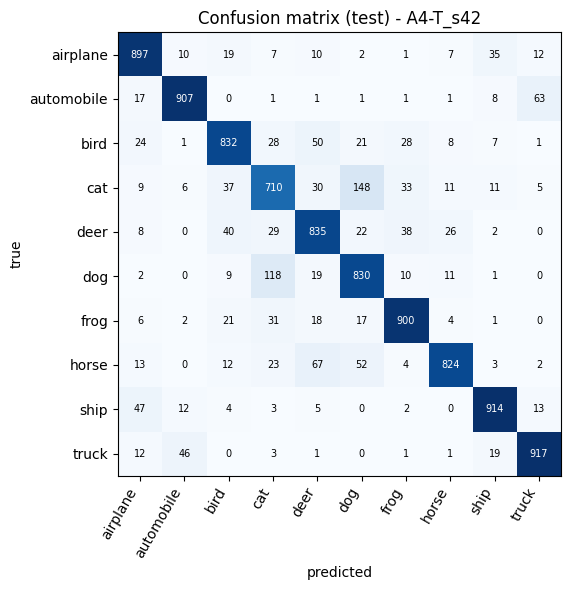

              precision    recall  f1-score   support

    airplane       0.87      0.90      0.88      1000
  automobile       0.92      0.91      0.91      1000
        bird       0.85      0.83      0.84      1000
         cat       0.75      0.71      0.73      1000
        deer       0.81      0.83      0.82      1000
         dog       0.76      0.83      0.79      1000
        frog       0.88      0.90      0.89      1000
       horse       0.92      0.82      0.87      1000
        ship       0.91      0.91      0.91      1000
       truck       0.91      0.92      0.91      1000

    accuracy                           0.86     10000
   macro avg       0.86      0.86      0.86     10000
weighted avg       0.86      0.86      0.86     10000



In [14]:
df = pd.DataFrame(RESULTS)
cand = df[df.run_id.str.endswith("_s42") | df.run_id.str.startswith("ARCH_")]
winner = cand.sort_values("best_val_acc", ascending=False).iloc[0]["run_id"]
if not os.path.exists(OUT + "/winner.txt"):
    open(OUT + "/winner.txt", "w").write(winner)
winner = open(OUT + "/winner.txt").read().strip()
print("Preselected winner (by validation accuracy):", winner)

if os.path.exists(OUT + "/test_result.json"):
    print("Test already evaluated once. Not running again:", open(OUT + "/test_result.json").read())
else:
    info = REG[winner]; clear()
    m = info["build"](); m.load_weights("%s/ckpt/%s.weights.h5" % (OUT, winner))
    ds_te = make_ds(x_test, y_test, info["size"], False, info["mode"])
    pred = m.predict(ds_te, verbose=0).argmax(1)
    acc = float((pred == y_test).mean()); f1 = float(f1_score(y_test, pred, average="macro"))
    json.dump({"winner": winner, "test_acc": acc, "test_macro_f1": f1}, open(OUT + "/test_result.json", "w"))
    print("TEST accuracy %.4f | macro-F1 %.4f" % (acc, f1))
    cm = confusion_matrix(y_test, pred)
    fig, ax = plt.subplots(figsize=(7, 6)); im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=60, ha="right"); ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES)
    for a in range(10):
        for b in range(10): ax.text(b, a, cm[a, b], ha="center", va="center", fontsize=7, color="white" if cm[a, b] > cm.max() / 2 else "black")
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Confusion matrix (test) - " + winner)
    plt.tight_layout(); plt.savefig(OUT + "/confusion_matrix.png", dpi=130); plt.show()
    print(classification_report(y_test, pred, target_names=CLASSES))

In [15]:
final = pd.DataFrame(RESULTS)
final["trainable/total params"] = final.trainable_params.map("{:,}".format) + " / " + final.total_params.map("{:,}".format)
cols = ["run_id", "architecture", "input_size", "seed", "trainable/total params", "epochs", "best_val_acc", "macro_f1",
        "final_train_acc", "gen_gap", "train_minutes", "peak_gpu_mb", "caveat"]
final[cols].round(4).to_csv(OUT + "/results_table.csv", index=False)
display(final[cols].round(4))
# reproducibility files
open("requirements.txt", "w").write("tensorflow\nscikit-learn\npandas\nnumpy\nmatplotlib\n")
open("README.md", "w").write("# CNN assignment 02\nOpen cnn_assignment.ipynb in Colab (T4 GPU), Runtime > Run all. Seed 42. Outputs in outputs/.\n")
import shutil; shutil.make_archive("outputs_bundle", "zip", OUT)
print("Zipped to outputs_bundle.zip (download it from the Colab file panel).")

,run_id,architecture,input_size,seed,trainable/total params,epochs,best_val_acc,macro_f1,final_train_acc,gen_gap,train_minutes,peak_gpu_mb,caveat
0,ARCH_AlexNet,AlexNet,96,42,"24,767,882 / 24,767,882",5,0.5757,0.5607,0.6757,0.1080,1.0977,4288.8899,"historical arch, different params/FLOPs; singl..."
1,ARCH_VGG16,VGG16,96,42,"50,415,434 / 50,415,434",5,0.5393,0.5333,0.5487,0.0093,5.5893,5811.6467,"historical arch, different params/FLOPs; singl..."
2,ARCH_InceptionV1,InceptionV1,96,42,"5,983,802 / 5,983,802",5,0.5340,0.5298,0.5571,0.0231,2.5778,5159.6227,"historical arch, different params/FLOPs; singl..."
3,ARCH_ResNet18,ResNet18,96,42,"11,181,642 / 11,191,242",5,0.5587,0.5547,0.8576,0.2989,1.8657,5183.1877,"historical arch, different params/FLOPs; singl..."
4,A0_s42,A0,64,42,"20,042 / 20,042",10,0.3483,0.3299,0.3404,-0.0079,0.6386,5192.0049,reference
5,A1_s42,A1,64,42,"20,138 / 20,330",10,0.4463,0.4474,0.4376,-0.0087,0.6196,5084.4547,A0 + BatchNorm
6,A2_s42,A2,64,42,"20,138 / 20,330",10,0.4510,0.4483,0.4293,-0.0217,1.1327,5205.5142,A1 + augmentation
7,A3-P_s42,A3-P,64,42,"482,730 / 484,074",10,0.6440,0.6351,0.7082,0.0642,2.8665,5439.9347,deeper plain; capacity changed vs A2
8,A3-R_s42,A3-R,64,42,"482,730 / 484,074",10,0.6027,0.6004,0.7042,0.1015,2.8489,5204.5844,A3-P + identity shortcuts (same params)
9,A0_s123,A0,64,123,"20,042 / 20,042",10,0.3673,0.3516,0.3587,-0.0063,0.5276,5074.0204,reference


Zipped to outputs_bundle.zip (download it from the Colab file panel).
